# Dogs vs Cats — Environment and Dataset Inspection

This notebook completes stages 2 and 3: verify the Python environment, inspect the course dataset, and display nine images from each class. Model training and dataset splitting are later stages.


In [1]:
from pathlib import Path
import sys, json, importlib.metadata as metadata
import numpy as np
import tensorflow as tf
import matplotlib
import sklearn
from PIL import Image
from IPython.display import Image as DisplayImage, display

ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src' / 'prepare_data.py').is_file()
versions = {name: metadata.version(name) for name in ['tensorflow-cpu', 'keras', 'numpy', 'matplotlib', 'scikit-learn', 'Pillow', 'ipykernel']}
print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print(json.dumps(versions, indent=2))


Python: 3.13.18
Interpreter: /workspaces/lucastheboss2020-image-classifier-project-tutorial/.venv/bin/python
{
  "tensorflow-cpu": "2.21.0",
  "keras": "3.15.1",
  "numpy": "2.5.4",
  "matplotlib": "3.11.2",
  "scikit-learn": "1.9.1",
  "Pillow": "13.0.0",
  "ipykernel": "7.4.0"
}


## Verify TensorFlow works

A small tensor calculation checks execution, not just installation. Codespaces can use the CPU for this setup stage.


In [2]:
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
value = tf.reduce_sum(tf.constant([[1., 2.], [3., 4.]])).numpy()
assert value == 10.0
print('TensorFlow computation passed:', float(value))
print('CPU devices:', len(tf.config.list_physical_devices('CPU')))
print('GPU devices:', len(tf.config.list_physical_devices('GPU')))


TensorFlow computation passed: 10.0
CPU devices: 1
GPU devices: 0


## Dataset inspection

Source: [4Geeks dogs-vs-cats archive](https://storage.googleapis.com/datascience-materials/dogs-vs-cats.zip). Labels come from `cat.` or `dog.` in filenames. The preparation script verifies and fully decodes every labeled image, records unreadable files, and preserves the originals. Raw data is excluded from Git.

To reproduce download and inspection from the repository root:
```bash
.venv/bin/python src/prepare_data.py
```


In [3]:
summary_path = ROOT / 'reports' / 'data_summary.json'
assert summary_path.exists(), 'Run .venv/bin/python src/prepare_data.py first.'
summary = json.loads(summary_path.read_text())
print('Labeled images:', summary['labeled_images'])
print('Class counts:', summary['class_counts'])
print('Valid images:', summary['valid_labeled_images'])
print('Unreadable images:', summary['corrupt_count'])
print('Width range:', summary['width_range'])
print('Height range:', summary['height_range'])
print('Image modes:', summary['image_modes'])
if summary['corrupt_images']:
    print('Unreadable file report:')
    print(json.dumps(summary['corrupt_images'], indent=2))


Labeled images: 25000
Class counts: {'cat': 12500, 'dog': 12500}
Valid images: 25000
Unreadable images: 0
Width range: [42, 1050]
Height range: [32, 768]
Image modes: {'RGB': 25000}


## Nine dog images


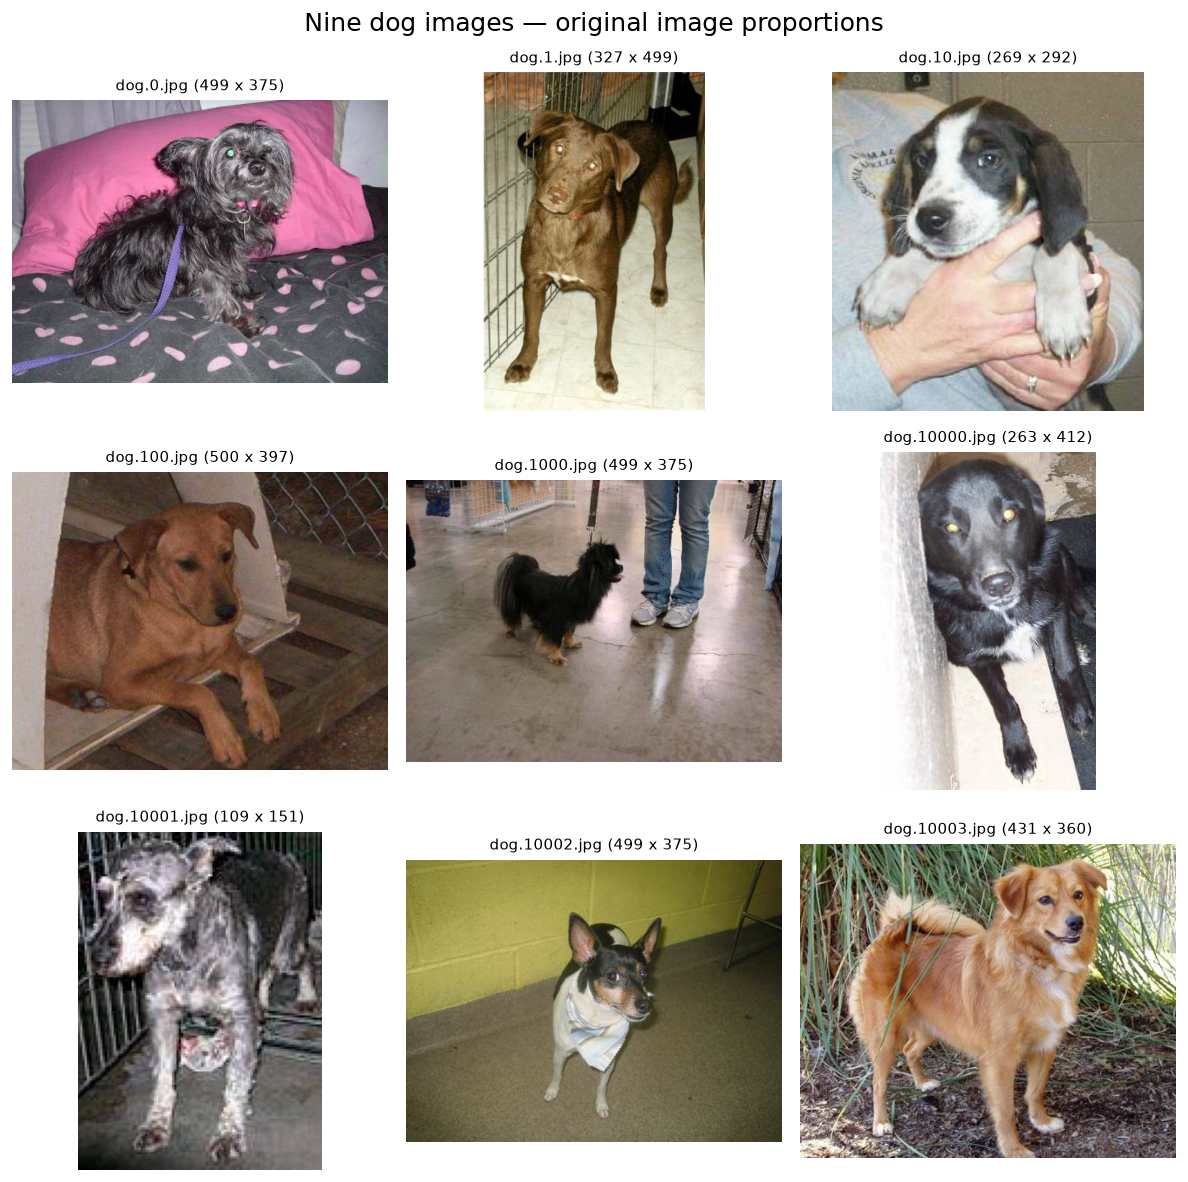

In [4]:
display(DisplayImage(filename=str(ROOT / 'reports' / 'figures' / 'dogs_grid.png')))


## Nine cat images


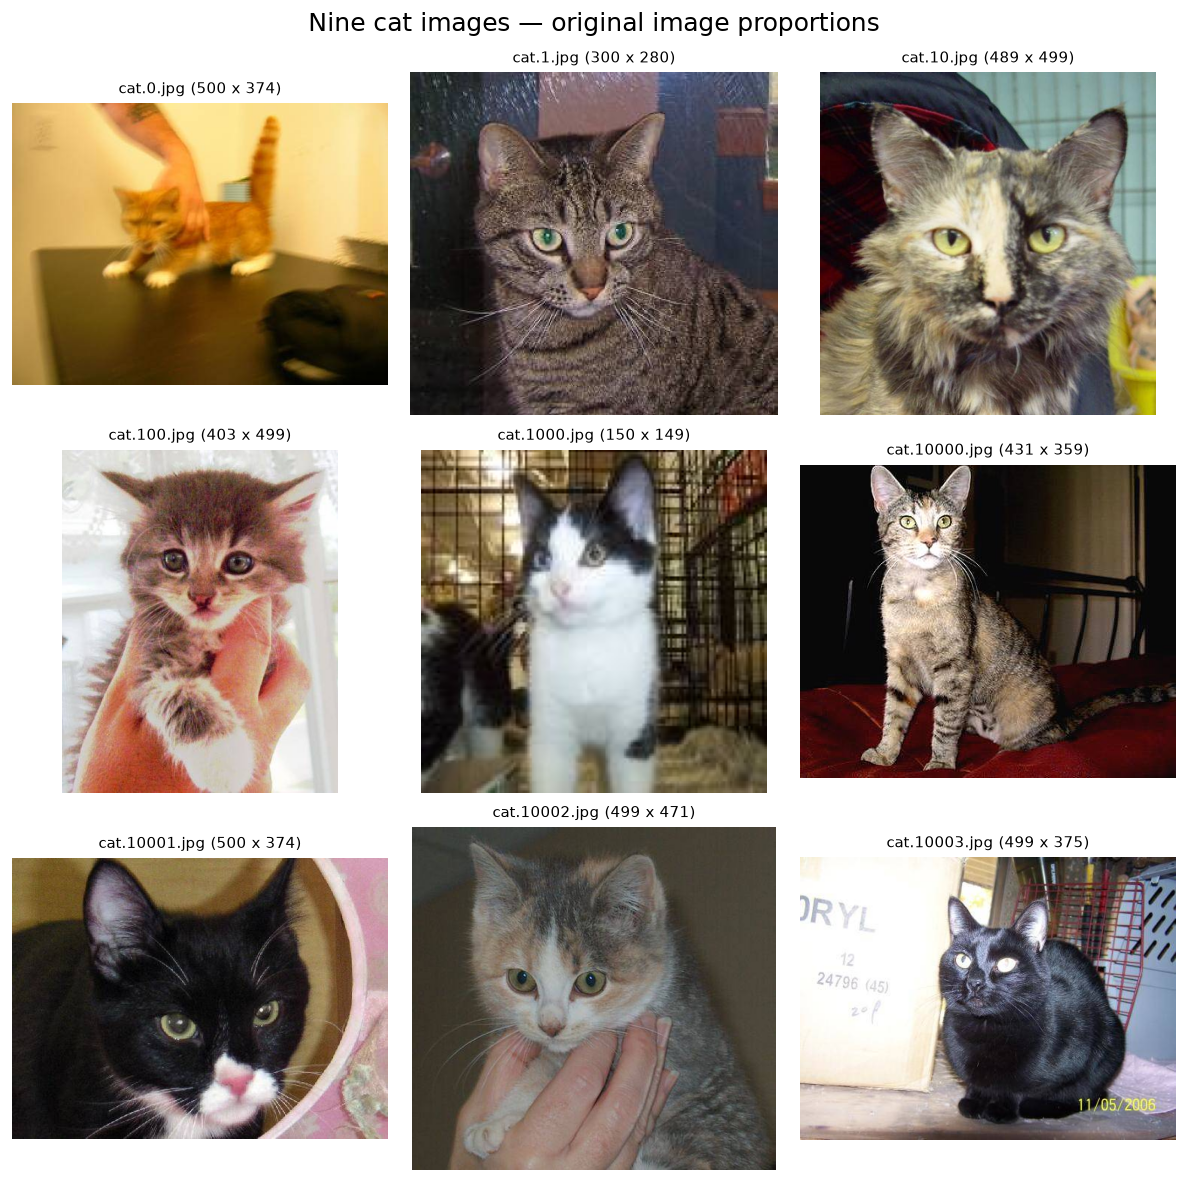

In [5]:
display(DisplayImage(filename=str(ROOT / 'reports' / 'figures' / 'cats_grid.png')))


## Observations and next stage

The images vary in dimensions, aspect ratio, background, and subject position. The report above records the class balance and image modes. Original files have not been resized or removed.

Next: exclude any unreadable files listed in the report, establish disjoint training/validation/test sets, and implement batched loading with images resized to 200 × 200 pixels. No model has been trained in this notebook.
